In [3]:
import matplotlib 
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np

In [4]:
import pandas as pd 
url = "data/nhanes_2015_2016.csv"
da = pd.read_csv(url)

### Studying Discrete Values 

In [5]:
gender = da['RIAGENDR']
gender.value_counts()

RIAGENDR
2    2976
1    2759
Name: count, dtype: int64

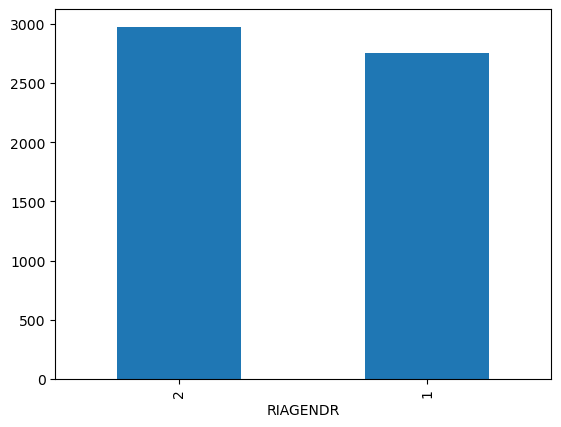

In [6]:
gender.value_counts().plot(kind='bar')
plt.show()

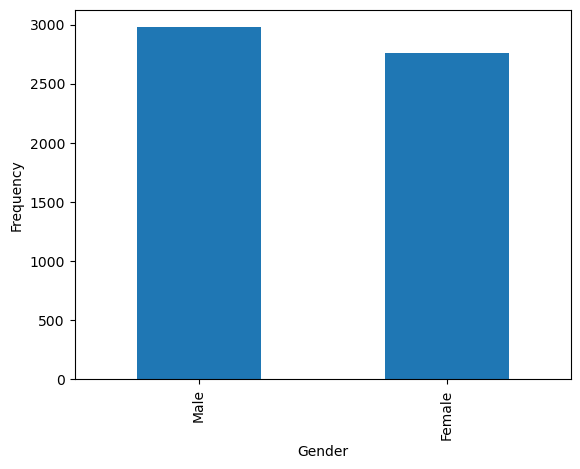

In [7]:
gender.value_counts().plot(kind='bar')
plt.xticks([0, 1], ['Male', 'Female']) # Show Male on 0th index and Female on 1st index
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.show()

### Most Common Value

In [8]:
sizes = np.array([22, 23, 29, 32, 39, 42, 42, 42, 42, 42, 42, 42, 42, 43, 44, 46, 51, 51, 55, 55, 57, 58, 78, 83, 97, 97])

In [7]:
sizes.mean()

np.float64(49.84615384615385)

In [8]:
from collections import Counter
cnt = Counter()

for size in sizes:
    cnt[size] += 1

cnt.most_common()    # index 0 is the most common (mode)

[(np.int64(42), 8),
 (np.int64(51), 2),
 (np.int64(55), 2),
 (np.int64(97), 2),
 (np.int64(22), 1),
 (np.int64(23), 1),
 (np.int64(29), 1),
 (np.int64(32), 1),
 (np.int64(39), 1),
 (np.int64(43), 1),
 (np.int64(44), 1),
 (np.int64(46), 1),
 (np.int64(57), 1),
 (np.int64(58), 1),
 (np.int64(78), 1),
 (np.int64(83), 1)]

In [9]:
#!pip install scipy 

In [10]:
from scipy import stats
stats.mode(sizes)    # index 0 has value, index 1 has count

ModeResult(mode=np.int64(42), count=np.int64(8))

In [11]:
gender.mode()

0    2
Name: RIAGENDR, dtype: int64

In [12]:
stats.mode(gender)

ModeResult(mode=np.int64(2), count=np.int64(2976))

### More Than One "Classes"

In [13]:
da['HIQ210'].unique()

array([ 2., nan,  1.,  9.])

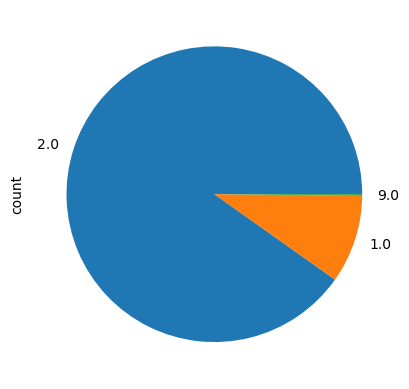

In [14]:
da['HIQ210'].value_counts().plot(kind='pie')
plt.show()

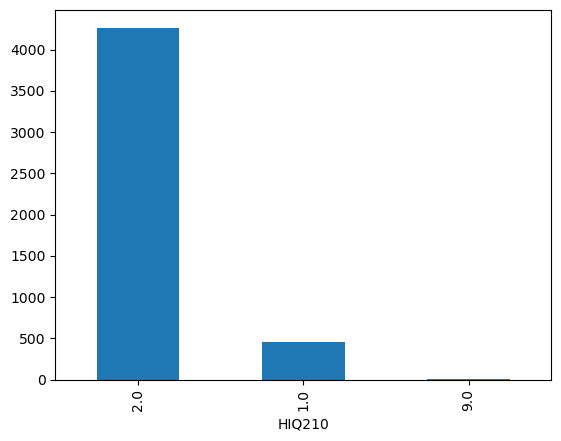

In [15]:
da['HIQ210'].value_counts().plot(kind='bar')
plt.show()

### Studying Real-Values Numbers

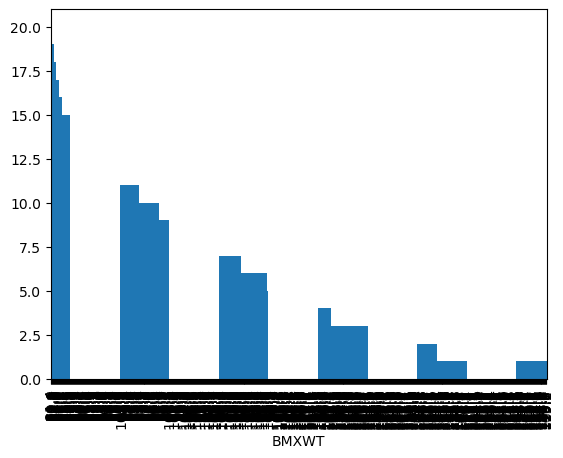

In [16]:
wt = da['BMXWT']
wt.value_counts().plot(kind='bar')    # does not work at all
plt.show()

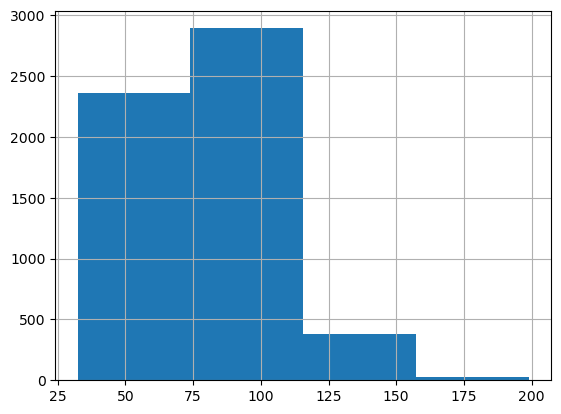

In [17]:
wt.hist(bins=4)
plt.show()

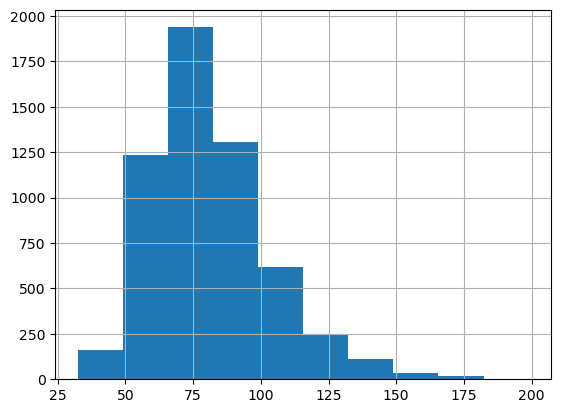

In [18]:
wt.hist(bins=10)
plt.show()

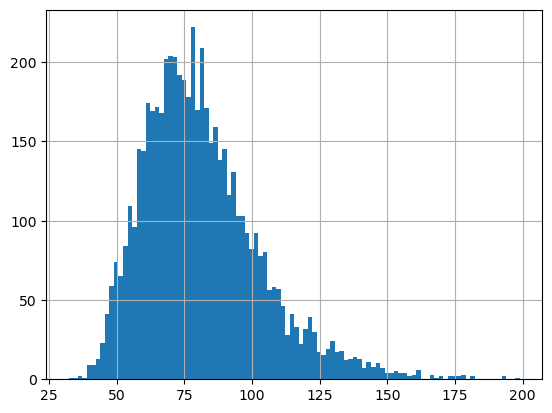

In [19]:
wt.hist(bins=100)
plt.show()

### Custom Matplotlib Histogram

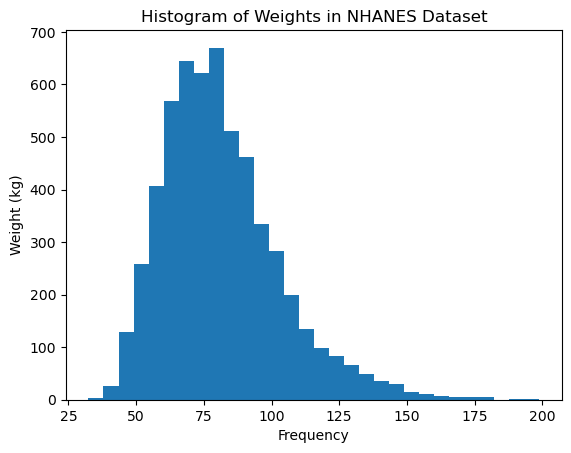

In [20]:
plt.hist(wt, bins=30)
plt.xlabel('Frequency')
plt.ylabel('Weight (kg)')
plt.title('Histogram of Weights in NHANES Dataset')
plt.show()

### Prettifying and Styling Matplotlib with Seaborn

In [9]:
#!pip install seaborn

In [22]:
import seaborn as sns 
sns.set(color_codes=True)
sns.set_style("white")    # for more styling options: https://seaborn.pydata.org/tutorial/aesthethics.html

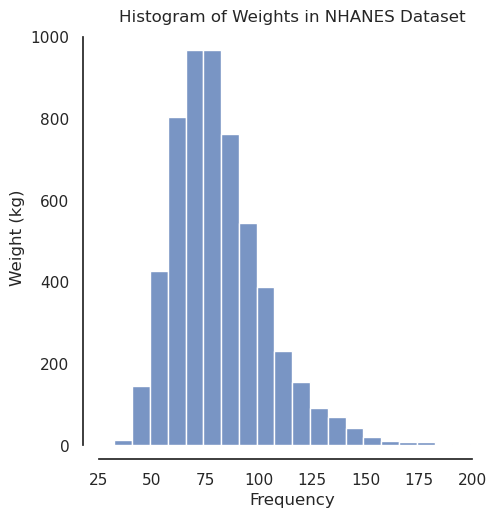

In [23]:
sns.displot(wt, bins=20)
plt.xlabel('Frequency')
plt.ylabel('Weight (kg)')
plt.title('Histogram of Weights in NHANES Dataset')
sns.despine(offset=10, trim=True);    # move axes away
plt.show()

### Studying Central Tendency

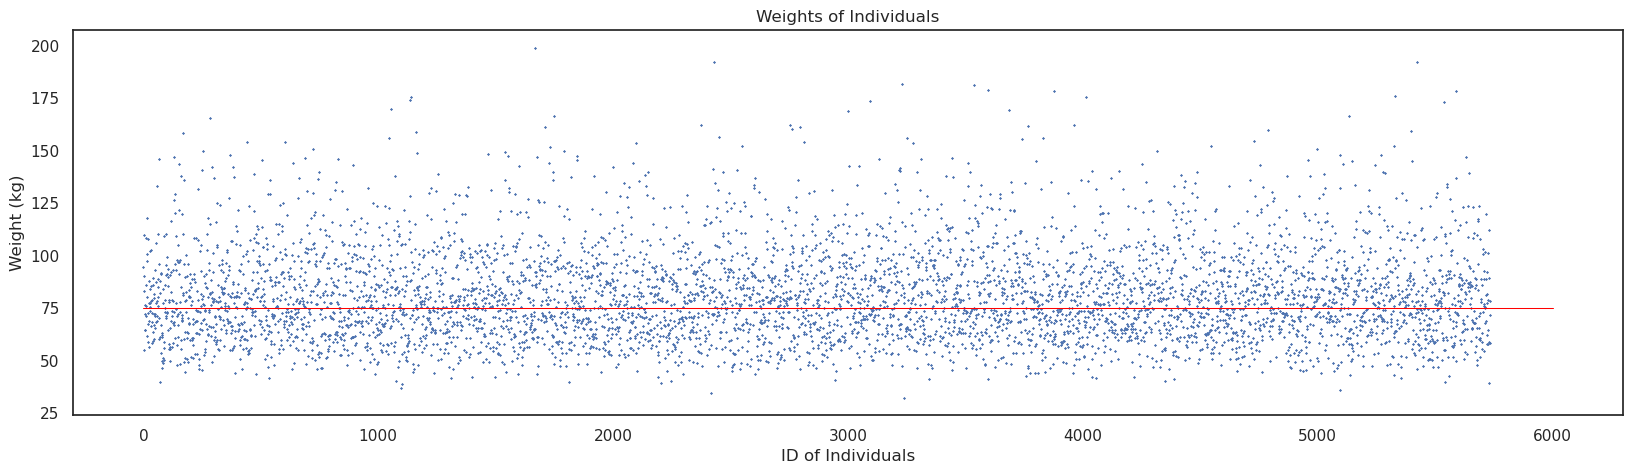

In [24]:
plt.figure(figsize=(20, 5))

x = range(da['BMXWT'].size)
y = da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title('Weights of Individuals')
plt.xlabel('ID of Individuals')
plt.ylabel('Weight (kg)')

# plotting the estimate line
p1 = (0, 75)
p2 = (6000, 75)
x_c, y_c = zip(p1, p2)
plt.plot(x_c, y_c, color='red', linewidth=0.75)
plt.show()

In [25]:
wt_mean = wt.mean()

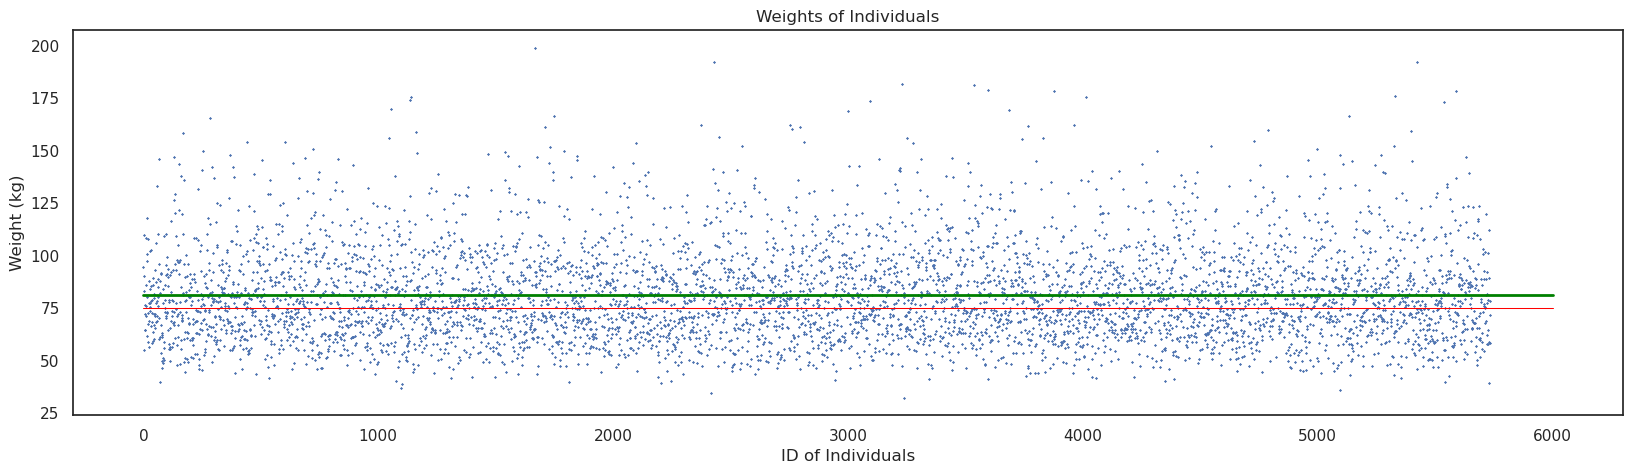

In [26]:
plt.figure(figsize=(20, 5))

x = range(da['BMXWT'].size)
y = da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title('Weights of Individuals')
plt.xlabel('ID of Individuals')
plt.ylabel('Weight (kg)')

# plotting the estimate line
x_c, y_c = ([0, 6000], [75, 75])
plt.plot(x_c, y_c, color='red', linewidth=0.75)

# plotting the estimate line
x_c, y_c = ([0, 6000], [wt_mean, wt_mean])
plt.plot(x_c, y_c, color='green', linewidth=2)

plt.show()

### Problem with Arithmetic Mean

In [27]:
nums = np.array([3, 4, 9, 17, 18, 20, 22, 23, 29, 32, 39, 42, 42, 42, 51, 97])
# just by changing 97 to 197 the mean becomes 36 from 30, which means it is an outlier

In [28]:
np.mean(nums)

np.float64(30.625)

In [29]:
np.median(nums) # Median is robust to outlier

np.float64(26.0)

### Visualizing Weights Data

In [30]:
wt.max()

198.9

In [31]:
wt.min()

32.4

In [32]:
wt.median()

78.2

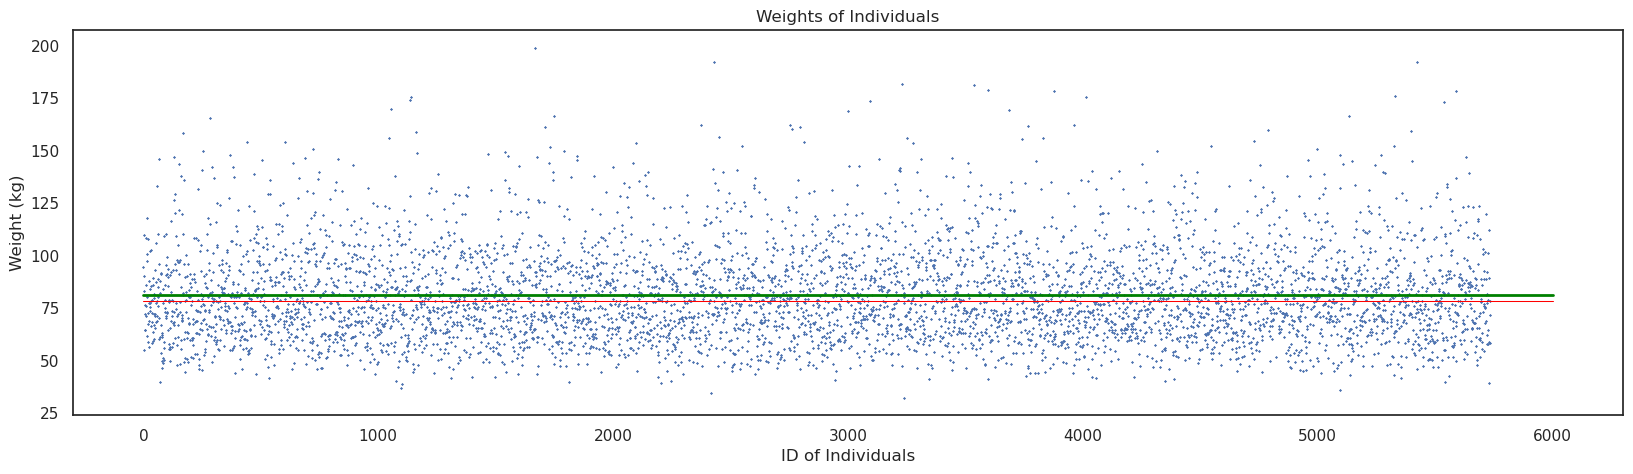

In [33]:
plt.figure(figsize=(20, 5))

x = range(da['BMXWT'].size)
y = da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title('Weights of Individuals')
plt.xlabel('ID of Individuals')
plt.ylabel('Weight (kg)')

# plotting the estimate line
x_c, y_c = ([0, 6000], [wt.median(), wt.median()])
plt.plot(x_c, y_c, color='red', linewidth=0.75)

# plotting the estimate line
x_c, y_c = ([0, 6000], [wt.mean(), wt.mean()])
plt.plot(x_c, y_c, color='green', linewidth=2)

plt.show()

### Quartiles and Boxplots

In [34]:
import statistics

In [35]:
statistics.quantiles(nums, n=4)

[np.float64(17.25), np.float64(26.0), np.float64(42.0)]

In [36]:
statistics.quantiles(wt, n=4)

[43.7, 50.8, 50.1]

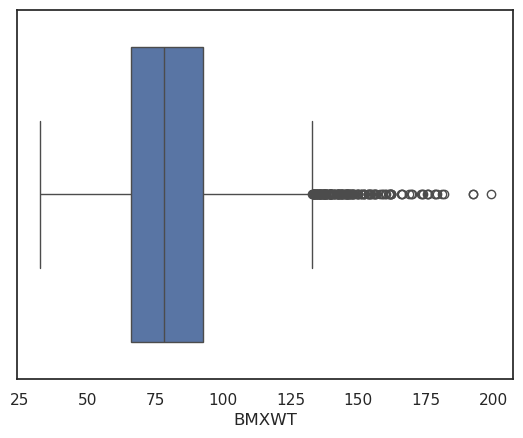

In [37]:
ax = sns.boxplot(x=wt)
plt.show()

In [38]:
male_wt = da.loc[da['RIAGENDR'] == 2, 'BMXWT']
male_wt.mean()

np.float64(76.51676280963693)

In [39]:
female_wt = da.loc[da['RIAGENDR'] == 1, 'BMXWT']
female_wt.mean()

np.float64(86.57326222876058)

/tmp/ipykernel_787/3545042263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="RIAGENDR", y="BMXWT", data=da, palette="Set3")


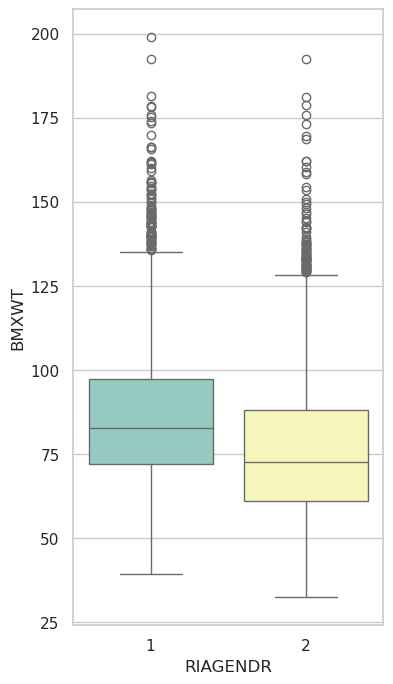

In [41]:
plt.figure(figsize=(4, 8))
sns.set_style("whitegrid")

ax = sns.boxplot(x="RIAGENDR", y="BMXWT", data=da, palette="Set3")
plt.show()

/tmp/ipykernel_787/3356826832.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="HIQ210", y="BMXWT", data=da, palette="Set3")


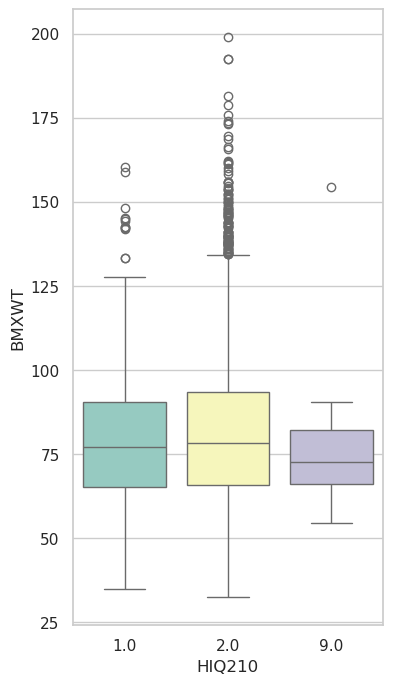

In [47]:
plt.figure(figsize=(4, 8))
sns.set_style("whitegrid")

ax = sns.boxplot(x="HIQ210", y="BMXWT", data=da, palette="Set3")
plt.show()